# Praktikum Kecerdasan Buatan
# Text Clustering for Movies

Topik : Text Clustering (K-Means)

Nama : Tika Altiora Sitanggang

NIM : 42324025

Program Studi : D3TI

## 1. Tujuan dan Gambaran Singkat

Tujuan praktikum ini adalah melakukan semua tahap klasterisasi teks, mulai dari membaca data sampai membaca hasil klasternya.

Data yang dipakai adalah tmdb_5000_movies.csv, yaitu data sekitar 5000 film. Teks yang dikelompokkan adalah kolom overview (sinopsis singkat film). Idenya, film yang sinopsisnya memakai kata-kata mirip akan masuk ke klaster yang sama, tanpa kita memberi label apa pun di awal. Karena itu ini termasuk unsupervised learning.

Tahapan yang dikerjakan di notebook ini:

1. Import library
2. Membaca dataset
3. Membersihkan data (cek nilai kosong)
4. Preprocessing teks (lowercase, hapus angka dan tanda baca, tokenisasi, lemmatization)
5. Mengubah teks menjadi angka dengan TF-IDF
6. Clustering dengan K-Means (jumlah klaster 2, sesuai modul)
7. Visualisasi dengan PCA
8. Membaca isi tiap klaster (kata penciri dan contoh film)
9. Mencoba jumlah klaster lain dan membandingkannya
10. Kesimpulan

Bagian 2 sampai 9 mengikuti kode di modul praktikum. Bagian 10 sampai 13 adalah tambahan untuk membantu membaca dan mengecek hasil. File tmdb_5000_movies.csv harus berada di folder yang sama dengan notebook ini.

## 2. Import Library

Pertama kita panggil semua library yang dibutuhkan.

1. pandas dan numpy untuk mengolah data dan angka.
2. re dan string untuk membersihkan teks (menghapus angka dan tanda baca).
3. word_tokenize dan WordNetLemmatizer dari NLTK untuk memecah teks menjadi kata dan mengubah kata ke bentuk dasarnya.
4. TfidfVectorizer untuk mengubah teks menjadi angka.
5. KMeans untuk proses clustering.
6. PCA untuk mengecilkan dimensi data supaya bisa digambar di grafik 2D.
7. silhouette_score untuk menilai kualitas klaster (dipakai di bagian 9).
8. matplotlib untuk membuat grafik.

In [19]:
# Import library
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

## 3. Download Resource NLTK

Tokenisasi dan lemmatization di NLTK membutuhkan beberapa resource tambahan. Sel di bawah ini mengunduhnya otomatis. Kalau sudah pernah terunduh, NLTK akan melewatinya, jadi aman dijalankan berkali-kali. Kalau komputer tidak terhubung internet dan resource belum ada, sel ini akan menampilkan False.

In [20]:
# Download resource NLTK yang dibutuhkan
for resource in ['punkt', 'punkt_tab', 'wordnet']:
    print(resource, nltk.download(resource, quiet=True))

punkt True
punkt_tab True
wordnet True


## 4. Membaca Dataset

Dataset dibaca dengan pd.read_csv, sama seperti di modul. Bedanya, modul memakai file Text.csv dengan kolom Message, sedangkan data yang diberikan untuk praktikum ini adalah tmdb_5000_movies.csv (data sekitar 5000 film dari TMDB). File aslinya diberikan dalam bentuk .gz, isinya sudah saya cocokkan dan sama persis dengan file .csv ini. Kalau ingin membaca langsung dari file .gz, cukup ganti file_path menjadi nama file .gz tersebut karena pandas bisa membacanya otomatis.

Dataset ini punya 20 kolom. Kolom yang berisi teks untuk diklasterkan adalah overview (sinopsis singkat film). Seperti di modul, kolom teks diganti namanya menjadi text. Dua kolom lain dipakai hanya untuk membantu membaca hasil:

1. title : judul film, untuk melihat contoh film di tiap klaster.
2. genres : genre film, tidak dipakai untuk clustering, hanya untuk mengecek hasil di bagian 13.

In [21]:
# Load dataset
file_path = "tmdb_5000_movies.csv"
df = pd.read_csv(file_path)

print("Jumlah baris dan kolom:", df.shape)

# Hanya mengambil kolom overview untuk klasterisasi (diganti namanya menjadi text, seperti di modul)
df = df.rename(columns={'overview': 'text'})
df[['title', 'text', 'genres']].head()

Jumlah baris dan kolom: (4803, 20)


,title,text,genres
0,Avatar,"In the 22nd century, a paraplegic Marine is di...","[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...","[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""..."
2,Spectre,A cryptic message from Bond’s past sends him o...,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."
3,The Dark Knight Rises,Following the death of District Attorney Harve...,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam..."
4,John Carter,"John Carter is a war-weary, former military ca...","[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."


Tabel di atas menunjukkan lima film pertama. Kolom text berisi sinopsis dalam bahasa Inggris, sedangkan kolom genres masih berupa teks dengan format JSON (daftar genre). Format ini akan kita rapikan nanti di bagian 9.

## 5. Cek dan Bersihkan Data

Sebelum diproses, kita cek dulu apakah ada nilai kosong pada kolom yang dipakai. Kalau ada sinopsis yang kosong, proses preprocessing akan error karena teks kosong tidak bisa diubah menjadi huruf kecil. Baris yang sinopsisnya kosong dibuang saja karena jumlahnya sangat sedikit. Kita juga cek apakah ada sinopsis yang dobel.

In [22]:
# Cek nilai kosong per kolom
print("Nilai kosong per kolom:")
print(df.isnull().sum())

Nilai kosong per kolom:
budget                     0
genres                     0
homepage                3091
id                         0
keywords                   0
original_language          0
original_title             0
text                       3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
dtype: int64


In [23]:
# Buang baris yang sinopsisnya kosong, lalu cek data dobel
df = df.dropna(subset=['text']).reset_index(drop=True)
print("Jumlah film setelah dibersihkan:", len(df))
print("Jumlah sinopsis dobel:", df['text'].duplicated().sum())

Jumlah film setelah dibersihkan: 4800
Jumlah sinopsis dobel: 0


Hasilnya, kolom text punya 3 nilai kosong dan barisnya sudah dibuang, sehingga tersisa 4800 film. Setelah itu dicek lagi dan tidak ada sinopsis yang dobel, jadi tidak ada data lain yang perlu dihapus. Sekarang data siap masuk tahap preprocessing.

## 6. Preprocessing Teks

Komputer tidak bisa langsung membandingkan kalimat, jadi teks perlu dirapikan dulu. Fungsi clean_text melakukan empat langkah:

1. Lowercasing : semua huruf dijadikan huruf kecil supaya kata Love dan love dianggap sama.
2. Hapus angka : angka biasanya tidak membantu membedakan tema film.
3. Hapus tanda baca : titik, koma, tanda kutip, dan sejenisnya dibuang.
4. Tokenisasi lalu lemmatization : kalimat dipecah menjadi kata, lalu tiap kata diubah ke bentuk dasarnya. Contohnya friends menjadi friend.

Lemmatizer NLTK secara bawaan menganggap semua kata sebagai kata benda. Akibatnya kata has berubah menjadi ha dan was menjadi wa. Ini hasil bawaan lemmatizer dan sengaja tidak diubah supaya kode tetap sama dengan modul. Dampaknya akan terlihat pada kata penciri di bagian 10.

In [24]:
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower()                                                  # Lowercasing
    text = re.sub(r'\d+', '', text)                                      # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation))     # Hapus tanda baca
    words = word_tokenize(text)                                          # Tokenisasi
    words = [lemmatizer.lemmatize(word) for word in words]               # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['text'].apply(clean_text)

Supaya terlihat apa yang berubah, sel berikut menampilkan satu sinopsis sebelum dan sesudah preprocessing.

In [25]:
# Bandingkan teks sebelum dan sesudah preprocessing
contoh = 0
print("Judul   :", df.loc[contoh, 'title'])
print()
print("Sebelum :", df.loc[contoh, 'text'])
print()
print("Sesudah :", df.loc[contoh, 'clean_text'])

Judul   : Avatar

Sebelum : In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization.

Sesudah : in the nd century a paraplegic marine is dispatched to the moon pandora on a unique mission but becomes torn between following order and protecting an alien civilization


Pada hasil di atas, huruf sudah kecil semua, angka dan tanda baca hilang, dan beberapa kata sudah diubah ke bentuk dasarnya. Teks ini sudah lebih bersih, tetapi masih berupa kata-kata. Langkah berikutnya mengubahnya menjadi angka.

## 7. Mengubah Teks Menjadi Angka (TF-IDF)

K-Means hanya bisa bekerja dengan angka, jadi setiap sinopsis diubah menjadi vektor memakai TF-IDF. Cara kerjanya secara singkat:

1. TF (term frequency) : seberapa sering sebuah kata muncul di satu sinopsis.
2. IDF (inverse document frequency) : seberapa jarang kata itu muncul di semua sinopsis. Kata yang muncul di hampir semua film mendapat bobot kecil, kata yang khas mendapat bobot besar.

Sesuai modul, TfidfVectorizer dipakai dengan stop_words='english', yaitu membuang kata umum bahasa Inggris seperti the, and, dan of memakai daftar stopwords dari sklearn.

In [26]:
# Konversi teks ke vektor TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')  # Menggunakan stopwords dari sklearn
X = vectorizer.fit_transform(df['clean_text'])

print("Ukuran matriks TF-IDF (jumlah film, jumlah kata):", X.shape)

Ukuran matriks TF-IDF (jumlah film, jumlah kata): (4800, 20249)


Hasilnya adalah sebuah matriks. Jumlah barisnya sama dengan jumlah film, dan jumlah kolomnya adalah jumlah kata unik yang tersisa. Setiap film sekarang diwakili oleh deretan angka bobot kata.

## 8. Clustering dengan K-Means

Sekarang masuk ke inti praktikum. K-Means mengelompokkan data ke dalam sejumlah klaster yang kita tentukan. Cara kerjanya:

1. Pilih titik pusat (centroid) awal sebanyak jumlah klaster.
2. Setiap film dimasukkan ke centroid terdekat.
3. Centroid dihitung ulang dari rata-rata anggota klasternya.
4. Langkah 2 dan 3 diulang sampai posisi centroid tidak berubah lagi.

Sesuai modul, jumlah klaster yang dipakai adalah 2 (num_clusters = 2). Parameter lainnya:

1. random_state=42 : supaya hasil sama setiap kali notebook dijalankan.
2. n_init=10 : K-Means dijalankan 10 kali dengan titik awal berbeda, lalu diambil hasil terbaik.

In [27]:
# Tentukan jumlah klaster
num_clusters = 2
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

# Jumlah film di tiap klaster
print("Jumlah film per klaster:")
print(df['cluster'].value_counts().sort_index())

Jumlah film per klaster:
cluster
0    3251
1    1549
Name: count, dtype: int64


Kolom cluster sudah ditambahkan ke data. Isinya angka 0 atau 1 yang menunjukkan film tersebut masuk ke klaster mana. Tabel di atas menunjukkan berapa banyak film di masing-masing klaster. Perlu diingat bahwa angka 0 dan 1 hanya nama klaster, bukan urutan atau tingkatan.

## 9. Visualisasi dengan PCA

Data TF-IDF punya ribuan kolom, sehingga tidak bisa digambar langsung. PCA dipakai untuk meringkasnya menjadi 2 komponen saja (PCA Component 1 dan 2) supaya bisa ditampilkan sebagai grafik titik. Setiap titik adalah satu film dan warnanya menunjukkan klasternya.

Karena ribuan dimensi dipaksa menjadi 2, sebagian informasi hilang. Jadi bentuk sebaran di grafik hanya gambaran kasar, bukan gambaran lengkap.

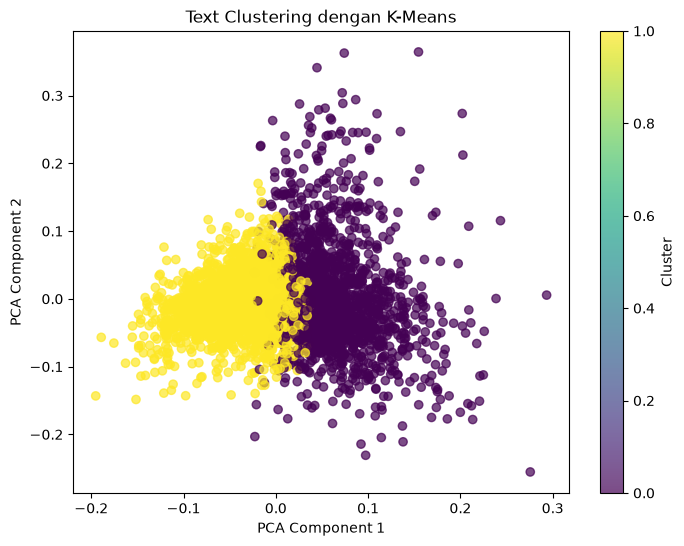

Informasi yang terwakili oleh 2 komponen: 0.68 %


In [17]:
# Visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()

print("Informasi yang terwakili oleh 2 komponen:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Cara membaca grafik: titik berwarna sama adalah film yang dikelompokkan bersama. Pada grafik terlihat kedua warna berkumpul di sisi yang berbeda (ungu di kiri, kuning di kanan), tetapi di bagian tengah keduanya saling menumpuk. Bentuk sebarannya berupa awan, tidak seperti bentuk huruf L pada gambar di modul. Perbedaan ini wajar karena modul memakai data pesan pendek (Text.csv), sedangkan di sini yang diklasterkan adalah sinopsis film yang lebih panjang dan kosakatanya lebih beragam. Angka di bawah grafik menunjukkan bahwa dua komponen PCA hanya menangkap bagian yang sangat kecil dari informasi asli (kurang dari 1 persen), jadi wajar kalau pemisahan klaster tidak tampak tegas di gambar. Untuk mengetahui apa yang sebenarnya membedakan klaster, kita perlu melihat isi teksnya, dan itu dilakukan di bagian berikutnya.

## 10. Membaca Isi Setiap Klaster

Grafik saja belum menjelaskan klaster itu berisi film seperti apa. Dua hal yang kita lihat:

1. Kata penciri : kata dengan bobot tertinggi pada centroid tiap klaster. Kata-kata ini menunjukkan tema utama klaster.
2. Contoh film : beberapa judul film yang ada di klaster tersebut.

Fungsi di bawah dibuat supaya bisa dipakai lagi untuk jumlah klaster yang berbeda. Kata ha, wa, dan doe (sisa lemmatization yang dijelaskan di bagian 6) serta kata film, story, dan movie (terlalu umum untuk sinopsis film) tidak ditampilkan di daftar kata penciri, supaya daftarnya lebih mudah dibaca. Pengaturan ini hanya memengaruhi tampilan, tidak memengaruhi hasil clustering.

In [29]:
# Fungsi untuk menampilkan kata penciri dan contoh film tiap klaster
terms = np.array(vectorizer.get_feature_names_out())

abaikan = {'ha', 'wa', 'doe', 'film', 'story', 'movie'}  # kata umum dan sisa lemmatization, tidak ditampilkan

def tampilkan_klaster(model, data, jumlah_kata=10, jumlah_film=5):
    urutan = model.cluster_centers_.argsort()[:, ::-1]
    for i in range(model.n_clusters):
        anggota = data[data['cluster'] == i]
        kata = [t for t in terms[urutan[i]] if t not in abaikan][:jumlah_kata]
        print(f"Klaster {i} ({len(anggota)} film)")
        print("  Kata penciri :", ", ".join(kata))
        print("  Contoh film  :", ", ".join(anggota['title'].head(jumlah_film)))
        print()

tampilkan_klaster(kmeans, df)

Klaster 0 (3251 film)
  Kata penciri : world, new, team, group, war, friend, man, life, year, help
  Contoh film  : Avatar, Spectre, The Dark Knight Rises, John Carter, Spider-Man 3

Klaster 1 (1549 film)
  Kata penciri : life, young, love, woman, man, family, new, friend, father, year
  Contoh film  : Pirates of the Caribbean: At World's End, Harry Potter and the Half-Blood Prince, Man of Steel, The Chronicles of Narnia: Prince Caspian, Pirates of the Caribbean: On Stranger Tides



Dari kata penciri di atas, kita bisa memberi gambaran tema tiap klaster:

1. Satu klaster berisi kata seperti world, team, group, dan war. Ini sinopsis bertema petualangan, aksi, dan misi kelompok.
2. Klaster lainnya berisi kata seperti life, young, love, woman, family, dan father. Ini sinopsis yang lebih berkisar pada kehidupan pribadi, keluarga, dan hubungan antar tokoh.

Nomor klaster bisa saja tertukar kalau versi library berbeda, tetapi temanya tetap sama. Dengan dua klaster saja, pembagiannya masih sangat umum. Karena itu pada bagian berikutnya kita coba jumlah klaster yang lain.

## 11. Mencoba Jumlah Klaster yang Berbeda

Modul memakai 2 klaster, tetapi jumlah itu belum tentu yang terbaik. Untuk membandingkan, kita jalankan K-Means dengan jumlah klaster 2 sampai 10 dan catat dua ukuran:

1. Inertia : jumlah jarak kuadrat tiap titik ke centroidnya. Makin kecil berarti titik makin rapat di dalam klasternya. Nilai ini selalu turun saat klaster ditambah, jadi yang dicari adalah titik tekuk (metode elbow), yaitu saat penurunannya mulai melandai.
2. Silhouette score : nilainya antara -1 sampai 1. Makin mendekati 1 berarti klaster makin terpisah jelas. Nilai mendekati 0 berarti klaster saling tumpang tindih.

In [30]:
# Bandingkan jumlah klaster 2 sampai 10
daftar_k = range(2, 11)
inertia_list = []
silhouette_list = []

for k in daftar_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    label = model.fit_predict(X)
    inertia_list.append(model.inertia_)
    silhouette_list.append(silhouette_score(X, label))

hasil_k = pd.DataFrame({
    'Jumlah Klaster': list(daftar_k),
    'Inertia': np.round(inertia_list, 1),
    'Silhouette': np.round(silhouette_list, 4)
})
hasil_k

,Jumlah Klaster,Inertia,Silhouette
0,2,4754.4,0.0010
1,3,4748.6,0.0009
2,4,4741.9,0.0011
3,5,4736.5,0.0012
4,6,4731.2,0.0015
5,7,4724.9,0.0018
6,8,4719.6,0.0022
7,9,4715.8,0.0020
8,10,4711.7,0.0024


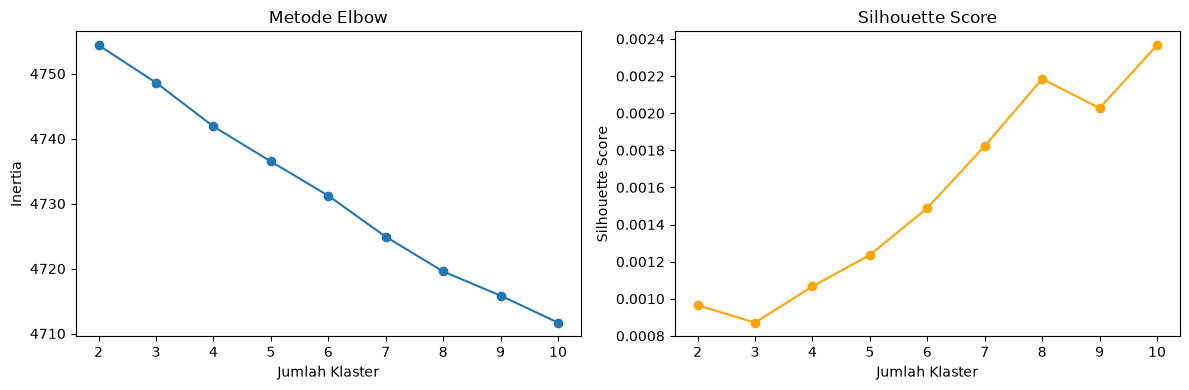

In [31]:
# Grafik elbow dan silhouette
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(list(daftar_k), inertia_list, marker='o')
ax[0].set_xlabel("Jumlah Klaster")
ax[0].set_ylabel("Inertia")
ax[0].set_title("Metode Elbow")

ax[1].plot(list(daftar_k), silhouette_list, marker='o', color='orange')
ax[1].set_xlabel("Jumlah Klaster")
ax[1].set_ylabel("Silhouette Score")
ax[1].set_title("Silhouette Score")

plt.tight_layout()
plt.show()

Cara membaca hasilnya:

1. Grafik elbow turun hampir lurus dan tidak punya tekukan yang jelas. Artinya tidak ada satu jumlah klaster yang tampak paling pas.
2. Nilai silhouette semuanya sangat kecil (mendekati 0). Ini berarti klaster saling tumpang tindih. Hal ini wajar untuk teks, karena satu film bisa memuat banyak tema sekaligus dan sinopsisnya pendek, sehingga batas antar kelompok tidak tegas.
3. Silhouette cenderung sedikit naik saat jumlah klaster bertambah, tetapi kenaikannya sangat kecil dan tidak cukup untuk dijadikan alasan memilih jumlah tertentu.

Karena penilaian angka tidak memberi jawaban tegas, saya mencoba 5 klaster sebagai pembanding. Alasannya, 5 klaster memberi kelompok yang masih mudah dibaca dan tidak terlalu banyak. Hasil 2 klaster dari modul tetap menjadi hasil utama praktikum ini.

In [32]:
# Percobaan pembanding dengan 5 klaster
kmeans5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster_5'] = kmeans5.fit_predict(X)

# tampilkan_klaster membaca kolom 'cluster', jadi kita siapkan salinan data khusus 5 klaster
df5 = df.copy()
df5['cluster'] = df5['cluster_5']
tampilkan_klaster(kmeans5, df5)

Klaster 0 (493 film)
  Kata penciri : woman, love, life, young, man, fall, new, meet, husband, year
  Contoh film  : Pirates of the Caribbean: On Stranger Tides, Jupiter Ascending, Maleficent, The Lovers, Pearl Harbor

Klaster 1 (886 film)
  Kata penciri : family, life, friend, new, young, father, mother, home, son, man
  Contoh film  : The Amazing Spider-Man, Robin Hood, Titanic, Monsters University, The Amazing Spider-Man 2

Klaster 2 (2510 film)
  Kata penciri : life, new, man, team, year, group, young, time, wife, way
  Contoh film  : The Dark Knight Rises, Spider-Man 3, Tangled, Harry Potter and the Half-Blood Prince, Superman Returns

Klaster 3 (619 film)
  Kata penciri : world, war, earth, planet, force, battle, alien, ii, new, army
  Contoh film  : Avatar, Pirates of the Caribbean: At World's End, Spectre, John Carter, Avengers: Age of Ultron

Klaster 4 (292 film)
  Kata penciri : school, high, town, student, small, teacher, girl, friend, college, life
  Contoh film  : Harry Po

Dengan 5 klaster, tema yang muncul lebih spesifik:

1. Klaster dengan kata woman, love, fall, meet, dan husband : film bertema cinta dan hubungan antar pasangan.
2. Klaster dengan kata family, father, mother, son, dan home : film bertema keluarga.
3. Klaster dengan kata world, war, earth, planet, force, battle, dan alien : film bertema perang dan fiksi ilmiah.
4. Klaster dengan kata school, high, student, teacher, dan college : film bertema sekolah dan remaja.
5. Klaster terbesar dengan kata umum seperti life, new, man, team, dan year : film dengan sinopsis yang beragam dan tidak punya kata yang khas.

Klaster terbesar seperti nomor 5 sering muncul pada clustering teks, karena film yang sinopsisnya tidak punya kata khusus akhirnya berkumpul di satu kelompok. Nomor klaster pada tabel bisa berbeda kalau versi library berbeda, tetapi temanya tetap sama.

## 12. Visualisasi PCA untuk 5 Klaster

Hasil 5 klaster juga kita gambar dengan PCA yang sama supaya bisa dibandingkan dengan grafik 2 klaster di bagian 9.

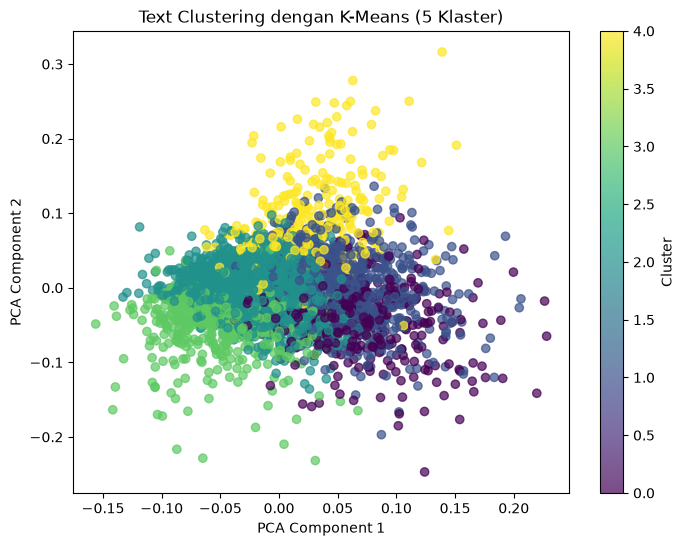

In [33]:
# Visualisasi 5 klaster (memakai hasil PCA yang sudah dihitung sebelumnya)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster_5'], cmap='viridis', alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means (5 Klaster)")
plt.colorbar(label='Cluster')
plt.show()

Grafik ini masih menunjukkan klaster yang saling menumpuk, sesuai dengan nilai silhouette yang kecil tadi. Jadi menambah jumlah klaster membuat tema lebih mudah dibaca dari kata penciri, tetapi tidak membuat klaster terpisah lebih jelas di grafik.

## 13. Pengecekan dengan Genre

Genre tidak dipakai saat clustering. Jadi kita bisa memakainya untuk mengecek hasil: kalau klaster benar-benar menangkap tema film, genre yang dominan di tiap klaster seharusnya berbeda.

Kolom genres masih berupa teks JSON, jadi kita ambil nama genrenya dulu. Genre Drama dan Comedy ada di banyak film, sehingga kalau hanya melihat genre terbanyak, hasilnya hampir sama di semua klaster. Karena itu kita pakai rasio: persentase genre di dalam klaster dibagi persentase genre yang sama di seluruh data. Rasio 2x berarti genre itu dua kali lebih sering muncul di klaster dibanding di keseluruhan data. Genre yang jumlahnya kurang dari 15 film di satu klaster tidak dihitung supaya tidak menyesatkan.

In [34]:
import json

# Ambil daftar nama genre dari teks JSON
def ambil_genre(teks):
    return [g['name'] for g in json.loads(teks)]

df['genre_list'] = df['genres'].apply(ambil_genre)

# Persentase tiap genre di seluruh data
persen_total = df['genre_list'].explode().value_counts() / len(df) * 100

# Untuk tiap klaster, cari 3 genre yang paling "menonjol" dibanding keseluruhan data
for i in range(5):
    anggota = df[df['cluster_5'] == i]
    jumlah = anggota['genre_list'].explode().value_counts()
    persen = jumlah / len(anggota) * 100
    rasio = (persen / persen_total[persen.index]).where(jumlah >= 15).dropna().sort_values(ascending=False)
    hasil = ", ".join(f"{g} ({persen[g]:.1f}%, {r:.2f}x)" for g, r in rasio.head(3).items())
    print(f"Klaster {i} ({len(anggota)} film):", hasil)

Klaster 0 (493 film): Romance (52.3%, 2.81x), Drama (58.0%, 1.21x), Comedy (43.2%, 1.20x)
Klaster 1 (886 film): Family (14.4%, 1.35x), Drama (57.7%, 1.21x), Romance (22.0%, 1.18x)
Klaster 2 (2510 film): Crime (19.6%, 1.35x), Documentary (3.0%, 1.35x), Thriller (32.3%, 1.22x)
Klaster 3 (619 film): War (12.9%, 4.31x), Science Fiction (30.9%, 2.77x), History (9.9%, 2.40x)
Klaster 4 (292 film): Music (8.6%, 2.22x), Romance (26.7%, 1.43x), Family (14.7%, 1.38x)


Cara membaca hasilnya: tiap baris berisi genre, persentasenya di klaster itu, dan rasionya terhadap seluruh data.

1. Klaster film perang dan fiksi ilmiah menonjol di War (sekitar 4 kali lipat), Science Fiction (sekitar 3 kali lipat), dan History. Ini cocok dengan kata war, planet, dan alien.
2. Klaster film cinta menonjol di Romance (sekitar 3 kali lipat), sesuai dengan kata love dan fall.
3. Klaster film sekolah dan remaja menonjol di Music (sekitar 2 kali lipat), Romance, dan Family, sesuai dengan tema sekolah dan kehidupan remaja.
4. Klaster keluarga menonjol di Family, tetapi rasionya tidak terlalu tinggi.
5. Klaster terbesar punya rasio yang rendah di semua genre, sesuai dengan sifatnya yang campuran.

Jadi sebagian besar klaster memang menangkap tema film, walaupun ada klaster yang pemisahannya lemah. Satu film bisa punya beberapa genre, sehingga persentase genre dalam satu klaster kalau dijumlahkan bisa lebih dari 100 persen.

## 14. Kesimpulan

1. Semua tahap klasterisasi teks sudah dikerjakan: membaca data, membersihkan data, preprocessing, TF-IDF, K-Means, visualisasi PCA, dan interpretasi klaster.
2. Dengan 2 klaster (sesuai modul), film terbagi menjadi kelompok bertema petualangan, aksi, dan misi kelompok, dan kelompok bertema kehidupan, keluarga, dan hubungan antar tokoh. Pembagian ini masih sangat umum.
3. Nilai silhouette yang sangat kecil dan elbow yang tidak jelas menunjukkan bahwa klaster pada teks sinopsis saling tumpang tindih. Penyebabnya, sinopsis pendek dan satu film bisa memuat banyak tema.
4. Dengan 5 klaster, tema yang muncul lebih spesifik (cinta, keluarga, perang dan fiksi ilmiah, sekolah dan remaja). Pengecekan dengan genre mendukung hal ini, misalnya genre War sekitar 4 kali lebih sering di klaster perang dan Romance sekitar 3 kali lebih sering di klaster cinta.
5. Kelemahan K-Means pada teks: jumlah klaster harus ditentukan sendiri, dan hasilnya sangat dipengaruhi oleh pemilihan kata (stopwords) saat TF-IDF. Karena itu langkah preprocessing dan interpretasi hasil sama pentingnya dengan algoritmanya.